In [86]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Exercício 1

1. Gere uma amostra de tamanho $K$ de uma variável com distribuição binomial negativa com parâmetros $p$ $r$ utilizando os três métodos vistos em sala: via Bernoullis, via soma de geométricas, via recursão.
2. Compare com uma amostra gerada pelo numpy usando histogramas.
3. Compare o tempo dos três métodos como visto nos labs anteriores.



In [87]:
np.random.seed(5)

(array([165., 258., 353., 132.,  62.,  20.,   5.,   4.,   0.,   1.]),
 array([ 8. , 10.5, 13. , 15.5, 18. , 20.5, 23. , 25.5, 28. , 30.5, 33. ]),
 <BarContainer object of 10 artists>)

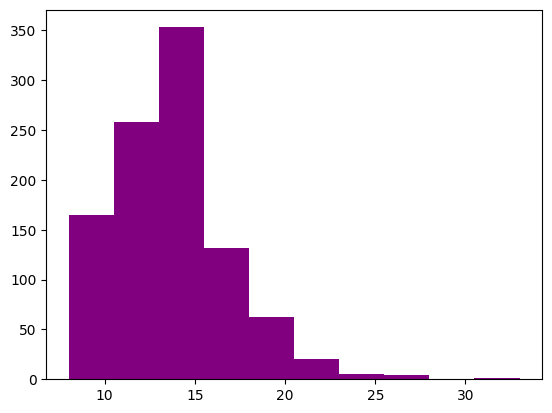

In [88]:
#Simulando via Bernoullis
inicio_ber = time.time()
amostra = []
N = 1000
for i in range(N):
  n = 0 ; s = 0
  r = 8
  p = 0.6
  while s<r:
    B = np.sum(np.random.uniform()<p)
    n = n + 1
    if B == 1:
      s += 1
  X = n
  amostra.append(X)
fim_ber = time.time()
time_ber = fim_ber - inicio_ber
plt.hist(amostra, bins=10, color = "purple")

(array([ 66., 209., 279., 212., 130.,  61.,  26.,  10.,   6.,   1.]),
 array([ 8. ,  9.9, 11.8, 13.7, 15.6, 17.5, 19.4, 21.3, 23.2, 25.1, 27. ]),
 <BarContainer object of 10 artists>)

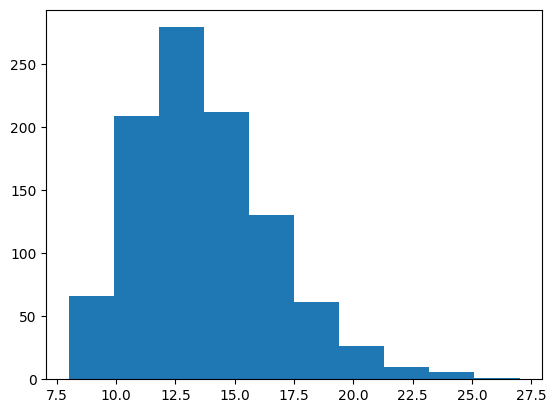

In [89]:
#Simulando via Geometrica
inicio_neg = time.time()
amostra_bineg = []
N = 1000
for i in range(N):
  p = 0.6 ; r = 8
  bn = []
  for j in range(r):
    u = np.random.uniform()
    x = np.floor(np.log(1-u)/np.log(1-p)) + 1
    bn.append(x)
  bn = np.sum(bn)
  amostra_bineg.append(bn)
fim_neg = time.time()
time_geo = fim_neg - inicio_neg
plt.hist(amostra_bineg, bins = 10)

(array([ 77., 225., 246., 141., 149., 100.,  20.,  29.,   8.,   5.]),
 array([ 8. ,  9.7, 11.4, 13.1, 14.8, 16.5, 18.2, 19.9, 21.6, 23.3, 25. ]),
 <BarContainer object of 10 artists>)

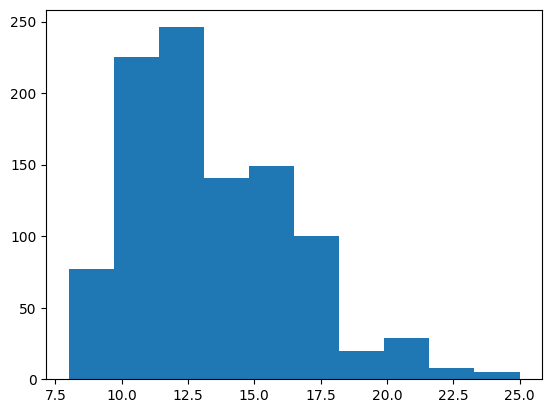

In [90]:
#Simulando via Inversão Recursiva
inicio_inversao = time.time()
amostra_rec = []
N = 1000
for i in range(N):
  r = 8 ; p = 0.6
  u = np.random.uniform()
  n = r ; pn = p**r ; F = pn
  while u > F:
    pn = pn * n*(1-p)/(n-r+1)
    n += 1
    F = F+pn
  x = n
  amostra_rec.append(x)
fim_inversao = time.time()
time_inversao = fim_inversao - inicio_inversao
plt.hist(amostra_rec)

(array([ 76., 235., 270., 196.,  77.,  84.,  42.,  13.,   4.,   3.]),
 array([ 0. ,  1.8,  3.6,  5.4,  7.2,  9. , 10.8, 12.6, 14.4, 16.2, 18. ]),
 <BarContainer object of 10 artists>)

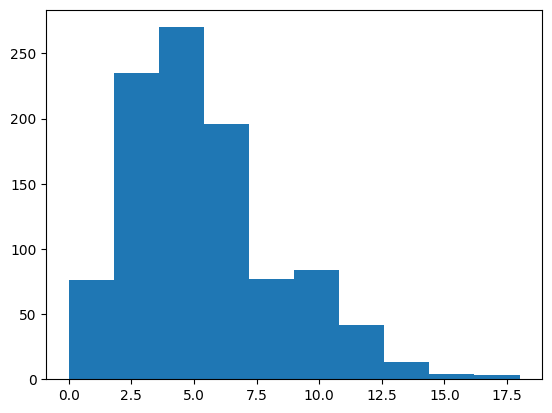

In [91]:
#Simulando via Numpy
plt.hist(np.random.negative_binomial(8, 0.6,1000))

In [92]:
print("Tempo Bernoulli: ", time_ber)
print("Tempo Geometrica: ", time_geo)
print("Tempo Inversão: ", time_inversao)

Tempo Bernoulli:  0.09409308433532715
Tempo Geometrica:  0.06194138526916504
Tempo Inversão:  0.0069391727447509766


# Exercício 2

1.  Gere uma amostra de tamanho $K$ de uma variável aleatória com distribuição hipergeométrica com parâmetros $M,N,n$ utilizando o método de embaralhamento de Fisher–Yates.
2.  No método de Fisher-Yates, no passo (a), a gente amostra um ponto para troca entre $i$ e $N$. Pense em qual seria o problema caso a gente sempre amostrasse entre $1$ e $N$. Compare o resultado final usando essas duas versões e uma amostra gerada pelo numpy.

In [93]:
hipergeo = np.random.hypergeometric(54,30,14,5000)

In [94]:
amostra = []
k = 5000
N = 54; M = 30
tam = 14
for j in range(k):
    lista = N*[1] + M*[0]
    n = len(lista)
    for i in range(0, n):
        u = np.random.uniform()
        index = int((n-i)*u + i)
        lista[i], lista[index] = lista[index], lista[i]
    hiper = np.sum(lista[0:tam])
    amostra.append(hiper)

(array([  15.,   90.,  265.,  541., 1005., 1128., 1097.,  594.,  205.,
          60.]),
 array([ 4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14.]),
 <BarContainer object of 10 artists>)

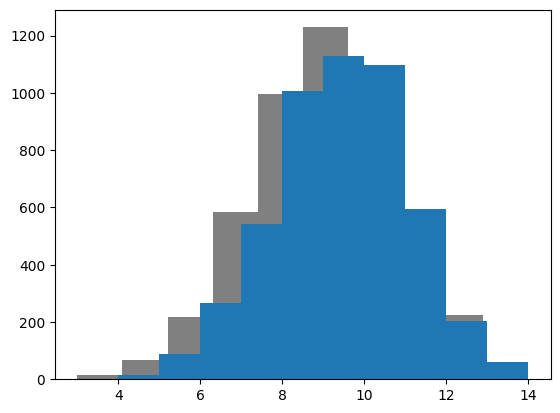

In [95]:
plt.hist(amostra, color = "gray")
plt.hist(hipergeo)

# Exercício 3

É intuitivo esperar que, quando o tamanho total da população $M+N$ cresce muito em relação ao tamanho da amostra $n$, o fato de a amostragem ser feita sem reposição passe a ter pouca importância, pois retirar um elemento altera muito pouco a composição da população restante. Nesse caso, cada retirada deve se comportar aproximadamente como um ensaio de Bernoulli independente, com probabilidade de sucesso

$$
p=\frac{N}{M+N}.
$$

Assim, esperamos que a distribuição hipergeométrica com parâmetros $M,N,n$ se aproxime de uma distribuição binomial com parâmetros $n$ e $p$.

Compare numericamente essas duas distribuições para valores crescentes de $M$ e $N$, mantendo aproximadamente constante a proporção

$$
\frac{N}{M+N}\to p,
$$

e mantendo $n$ fixo. Verifique, por meio de simulações, se a aproximação pela distribuição binomial melhora à medida que $M+N$ aumenta.


In [96]:
def hipergeometrica(N,n):
  amostra = []
  k = 1000
  M = n - N
  tam = 14
  for j in range(k):
      lista = N*[1] + M*[0]
      n = len(lista)
      for i in range(0, n):
          u = np.random.uniform()
          index = int((n-i)*u + i)
          lista[i], lista[index] = lista[index], lista[i]
      hiper = np.sum(lista[0:tam])
      amostra.append(hiper)
  return amostra

In [101]:
amostra1 = hipergeometrica(30,100)
amostra2 = hipergeometrica(150,500)
amostra3 = hipergeometrica(300,1000)

(array([ 10.,  50., 109., 195., 239., 205., 106.,  61.,  18.,   7.]),
 array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]),
 <BarContainer object of 10 artists>)

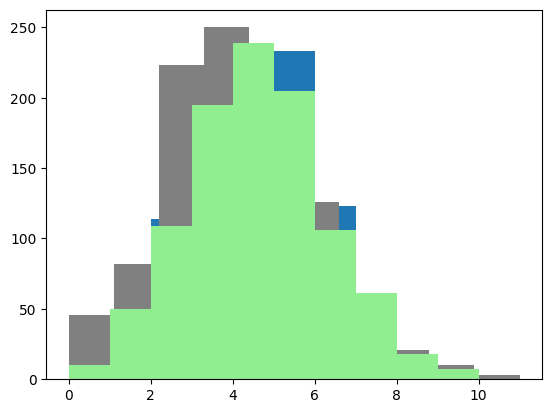

In [104]:
plt.hist(amostra1)
plt.hist(amostra2,color = "gray")
plt.hist(amostra3,color = "lightgreen")

(array([  5.,  17.,  52., 150., 198., 280., 184.,  78.,  27.,   9.]),
 array([252. , 261.2, 270.4, 279.6, 288.8, 298. , 307.2, 316.4, 325.6,
        334.8, 344. ]),
 <BarContainer object of 10 artists>)

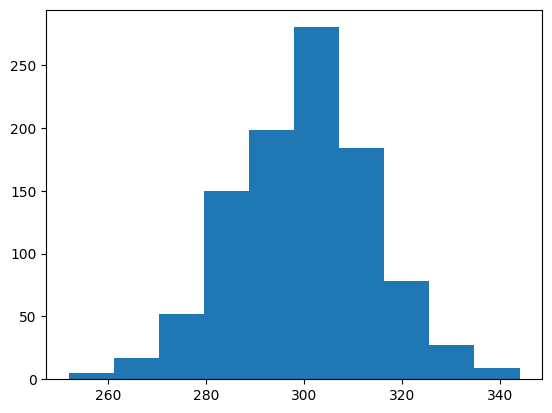

In [107]:
plt.hist(np.random.binomial(1000,0.3,1000))